[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder

# Read the data

In [ ]:
df = pd.read_csv('athlete_events.csv')
df.head(10)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
5,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
6,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,Speed Skating Women's 500 metres,NaN
7,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
8,5,Christine Jacoba Aaftink,F,27.0,185.0,82.0,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,Speed Skating Women's 500 metres,NaN
9,5,Christine Jacoba Aaftink,F,27.0,185.0,82.0,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,"Speed Skating Women's 1,000 metres",NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


### Don't forget to drop duplicates first

In [ ]:
df = df.drop_duplicates()
df.info()
df.head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 269731 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      269731 non-null  int64  
 1   Name    269731 non-null  object 
 2   Sex     269731 non-null  object 
 3   Age     260416 non-null  float64
 4   Height  210917 non-null  float64
 5   Weight  208204 non-null  float64
 6   Team    269731 non-null  object 
 7   NOC     269731 non-null  object 
 8   Games   269731 non-null  object 
 9   Year    269731 non-null  int64  
 10  Season  269731 non-null  object 
 11  City    269731 non-null  object 
 12  Sport   269731 non-null  object 
 13  Event   269731 non-null  object 
 14  Medal   39772 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 32.9+ MB


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
5,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
6,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,Speed Skating Women's 500 metres,NaN
7,5,Christine Jacoba Aaftink,F,25.0,185.0,82.0,Netherlands,NED,1992 Winter,1992,Winter,Albertville,Speed Skating,"Speed Skating Women's 1,000 metres",NaN
8,5,Christine Jacoba Aaftink,F,27.0,185.0,82.0,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,Speed Skating Women's 500 metres,NaN
9,5,Christine Jacoba Aaftink,F,27.0,185.0,82.0,Netherlands,NED,1994 Winter,1994,Winter,Lillehammer,Speed Skating,"Speed Skating Women's 1,000 metres",NaN


# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [ ]:
df.isnull().sum()

,0
ID,0
Name,0
Sex,0
Age,9315
Height,58814
Weight,61527
Team,0
NOC,0
Games,0
Year,0


### Number of males and females

In [ ]:
df['Sex'].value_counts()

,count
Sex,
M,195353
F,74378


### How many cities do we have and what are they ?

In [ ]:
unique_cities = df['City'].unique()
print(f"Number of cities: {len(unique_cities)}")
print("Cities:", unique_cities)

Number of cities: 42
Cities: ['Barcelona' 'London' 'Antwerpen' 'Paris' 'Calgary' 'Albertville'
 'Lillehammer' 'Los Angeles' 'Salt Lake City' 'Helsinki' 'Lake Placid'
 'Sydney' 'Atlanta' 'Stockholm' 'Sochi' 'Nagano' 'Torino' 'Beijing'
 'Rio de Janeiro' 'Athina' 'Squaw Valley' 'Innsbruck' 'Sarajevo'
 'Mexico City' 'Munich' 'Seoul' 'Berlin' 'Oslo' "Cortina d'Ampezzo"
 'Melbourne' 'Roma' 'Amsterdam' 'Montreal' 'Moskva' 'Tokyo' 'Vancouver'
 'Grenoble' 'Sapporo' 'Chamonix' 'St. Louis' 'Sankt Moritz'
 'Garmisch-Partenkirchen']


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [ ]:
athletes_per_year = df.groupby('Year')['ID'].nunique()
display(athletes_per_year)

,ID
Year,
1896,176
1900,1224
1904,650
1906,841
1908,2024
1912,2409
1920,2676
1924,3565
1928,3703


### Which athlete participated the most? (his/her name and ID)

In [ ]:
most_participated_id = df['ID'].value_counts().idxmax()
participation_count = df['ID'].value_counts().max()
athlete_info = df[df['ID'] == most_participated_id].iloc[0]
print(f"ID: {most_participated_id}")
print(f"Name: {athlete_info['Name']}")
print(f"Participations: {participation_count}")

ID: 106296
Name: Heikki Ilmari Savolainen
Participations: 39


# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
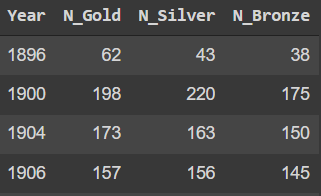

In [ ]:
medal_counts = df.groupby(['Year', 'Medal']).size().unstack(fill_value=0)
# Reorder columns to standard Gold, Silver, Bronze if present
columns_order = [col for col in ['Gold', 'Silver', 'Bronze'] if col in medal_counts.columns]
if columns_order:
    medal_counts = medal_counts[columns_order]
display(medal_counts)

Medal,Gold,Silver,Bronze
Year,,,
1896,62,43,38
1900,198,220,175
1904,173,163,150
1906,157,156,145
1908,294,281,256
1912,326,315,300
1920,493,448,367
1924,332,319,311
1928,275,267,281


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

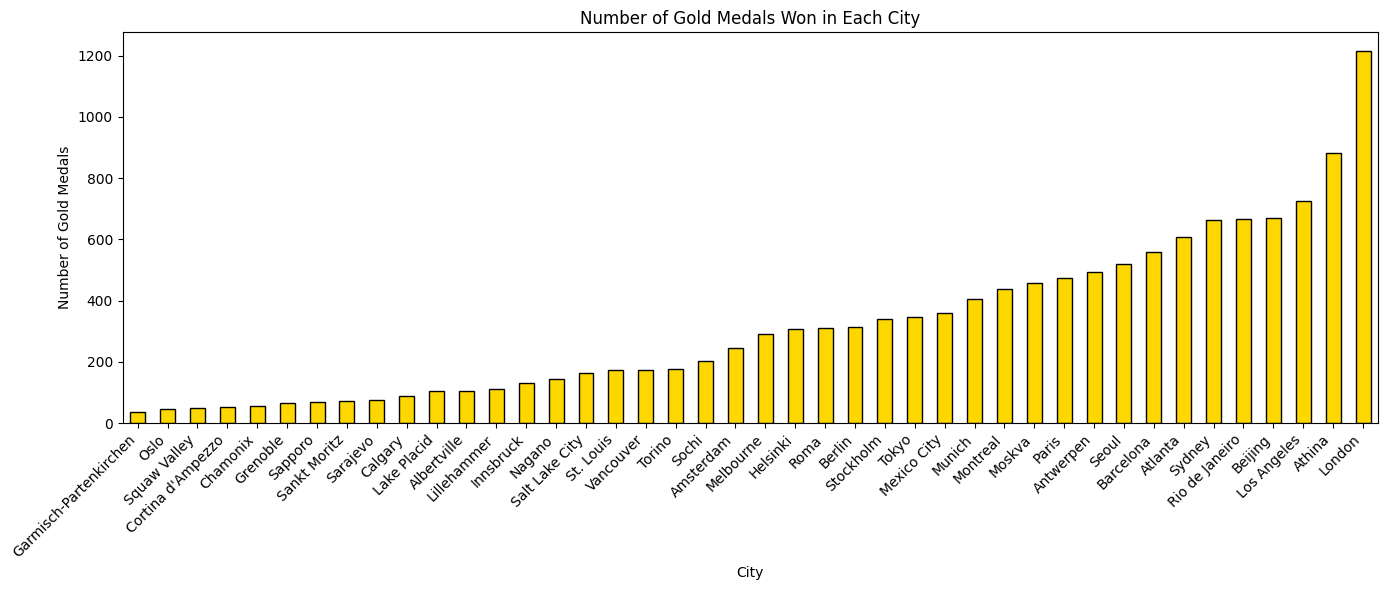

In [ ]:
import matplotlib.pyplot as plt
gold_winners = df[df['Medal'] == 'Gold']

gold_by_city = gold_winners.groupby('City')['ID'].count().sort_values()

# Plotting
plt.figure(figsize=(14, 6))
gold_by_city.plot(kind='bar', color='gold', edgecolor='black')
plt.title('Number of Gold Medals Won in Each City')
plt.xlabel('City')
plt.ylabel('Number of Gold Medals')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Find the total missing data for each year?

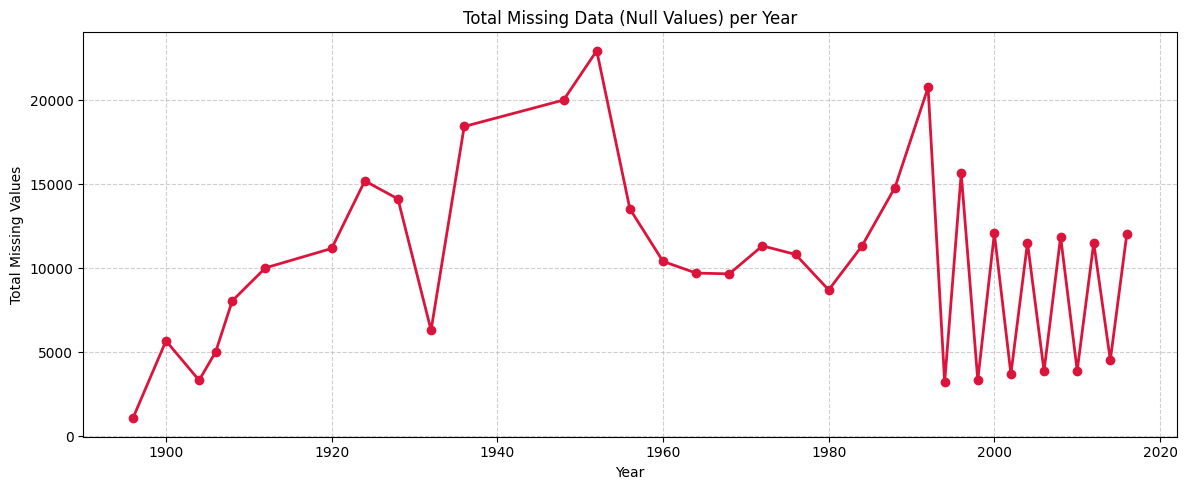

In [ ]:
import matplotlib.pyplot as plt

# Sum up all missing (null) values per row, then group by Year and sum them
missing_per_year = df.isnull().sum(axis=1).groupby(df['Year']).sum()

# Plot the results
plt.figure(figsize=(12, 5))
plt.plot(missing_per_year.index, missing_per_year.values, marker='o', color='crimson', linewidth=2)
plt.title('Total Missing Data (Null Values) per Year')
plt.xlabel('Year')
plt.ylabel('Total Missing Values')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

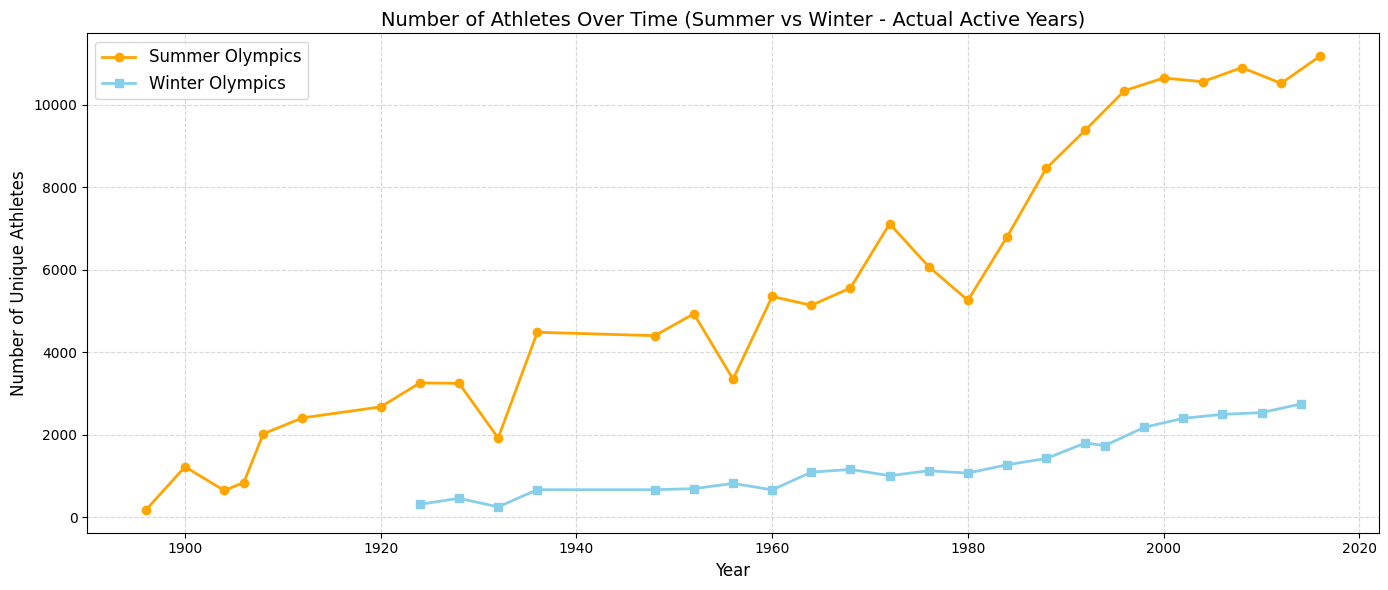

In [ ]:
import matplotlib.pyplot as plt

# Filter active years for each season to avoid the zigzag drops to zero
summer_data = df[df['Season'] == 'Summer'].groupby('Year')['ID'].nunique()
winter_data = df[df['Season'] == 'Winter'].groupby('Year')['ID'].nunique()

plt.figure(figsize=(14, 6))
plt.plot(summer_data.index, summer_data.values, marker='o', label='Summer Olympics', color='orange', linewidth=2)
plt.plot(winter_data.index, winter_data.values, marker='s', label='Winter Olympics', color='skyblue', linewidth=2)

plt.title('Number of Athletes Over Time (Summer vs Winter - Actual Active Years)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Unique Athletes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()